In [1]:
from dglgc_funcs import update_glycogen, table1, table2
from dglgc_funcs import get_values, lgs_model
import cobra
import numpy as np
import pandas as pd
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:

syn6803 = cobra.io.read_sbml_model(
    "models/Synechocystis_6803_constrained.xml"
)
universal = cobra.io.read_sbml_model(
    "models/universal_model_io.sbml"
)

No objective coefficients in model. Unclear what should be optimized


In [3]:
efe_ratio = 3  # 3 for 3:1 ratio, 7 for 7:3

In [4]:
(gua := universal.metabolites.get_by_id("M02035_c")).formula = "CH6N3"
gua.charge = 1
(ethe:= universal.metabolites.get_by_id("ethe_c")).formula = "C2H4"

efe_tomas = cobra.core.Reaction("EFE")
efe_tomas.name = "Ethylene Forming Enzyme (Tomas)"
efe_tomas.add_metabolites({
    syn6803.metabolites.get_by_id("akg_c"): -10,
    syn6803.metabolites.get_by_id("arg__L_c"): -3,
    syn6803.metabolites.get_by_id("o2_c"): -10,
    syn6803.metabolites.get_by_id("h_c"): -11,
    syn6803.metabolites.get_by_id("co2_c"): 24,
    universal.metabolites.get_by_id("ethe_c"): 7,
    syn6803.metabolites.get_by_id("succ_c"): 3,
    universal.metabolites.get_by_id("M02035_c"): 3,  # guanidine
    syn6803.metabolites.get_by_id("1pyr5c_c"): 3,
    syn6803.metabolites.get_by_id("h2o_c"): 10
})

efe_31 = cobra.core.Reaction("EFE")
efe_31.name = "Ethylene Forming Enzyme"
efe_31.add_metabolites({
    syn6803.metabolites.get_by_id("akg_c"): -3,
    syn6803.metabolites.get_by_id("arg__L_c"): -1,
    syn6803.metabolites.get_by_id("o2_c"): -3,
    syn6803.metabolites.get_by_id("h_c"): -3,
    syn6803.metabolites.get_by_id("co2_c"): 7,
    universal.metabolites.get_by_id("ethe_c"): 2,
    syn6803.metabolites.get_by_id("succ_c"): 1,
    universal.metabolites.get_by_id("M02035_c"): 1,  # Guanidine
    syn6803.metabolites.get_by_id("1pyr5c_c"): 1,
    syn6803.metabolites.get_by_id("h2o_c"): 3,
})

gdmh = cobra.core.Reaction("GDMH")
gdmh.name = "Guanidine hydrolase "
gdmh.add_metabolites({
    syn6803.metabolites.get_by_id("h2o_c"): -1,
    universal.metabolites.get_by_id("M02035_c"): -1,  # Guanidine
    syn6803.metabolites.get_by_id("nh4_c"): 1,
    syn6803.metabolites.get_by_id("urea_c"): 1
})

match efe_ratio:
    case 3:
        efe = efe_31
    case 7:
        efe = efe_tomas

syn6803.add_reactions([efe, gdmh])

In [5]:
met_dict = {
    "Glycogen": ("glycogen_c", None),
    "Pyruvate": ("pyr_c", None),
    "Succinate": ("succ_c", None),
    "2-Oxoglutarate": ("akg_c", None),
    "Fumarate": ("fum_c", None),
    "Malate": ("mal__L_c", None),
    "Citrate": ("cit_c", None),
    "Lipid": ("palmACP_c", "ACP_c"),
    "Lipid elongation": ("palmACP_c", "myrsACP_c"),
    "Additional double bond": ("hdeceACP_c", "palmACP_c"),
    "Protein (per AA)": ("bm_pro_c", None),
    "Ethylene": ("ethe_c", None)
}

In [6]:
rows = []
for name, (moi, add_m) in met_dict.items():
    row = table1(syn6803, name, moi, add_m)
    rows.append(row)

table1_df = pd.DataFrame(rows)

print(table1_df.to_string(index=False))

            Metabolite  C atoms  ATP demand  NADPH demand  ATP/NADPH    Photons
              Glycogen        6   18.000000     12.000000   1.500000  51.000000
              Pyruvate        3    7.000000      5.100000   1.372549  20.916667
             Succinate        4   14.000000      9.000000   1.555556  34.333333
        2-Oxoglutarate        5   14.000000      8.200000   1.707317  36.833333
              Fumarate        4    8.000000      6.200000   1.290323  24.833333
                Malate        4    8.000000      6.200000   1.290323  24.833333
               Citrate        6   14.000000      9.300000   1.505376  39.583333
                 Lipid       16   55.000000     46.000000   1.195652 184.000000
      Lipid elongation       16    7.000000      6.000000   1.166667  24.000000
Additional double bond       16    0.857143      0.571429   1.500000   4.000000
      Protein (per AA)        0   17.232937      9.198595   1.873431  63.571085
              Ethylene        2   19.000

In [7]:

syn6803 = cobra.io.read_sbml_model(
    "models/Synechocystis_6803_constrained.xml"
)
syn6803.add_reactions([efe, gdmh])

In [8]:

growth_WT = 0.048681058969584315
light_WT = 200
glycogen_WT = 13.7936

In [9]:
# generate the WT solution
growth_85 = growth_WT * (100-glycogen_WT)/100
with syn6803:
    syn6803.objective = "EX_photon_e1_e"
    syn6803.add_boundary(syn6803.metabolites.get_by_id("bm_glycogen_c"), type="demand")
    
    syn6803.reactions.get_by_id("EX_biomass_e").lower_bound = growth_85
    syn6803.reactions.get_by_id("DM_bm_glycogen_c").lower_bound = growth_WT * glycogen_WT/100  # * glycogen_mol
    syn6803 = update_glycogen(syn6803, 0)
    solution_WT = syn6803.optimize()
    PHOTONS_WT = solution_WT.objective_value
    glycogen_flux_WT = solution_WT.fluxes["BM0010"] * -syn6803.reactions.BM0010.metabolites[syn6803.metabolites.glycogen_c]
    
    nadph_WT, atp_WT, C_uptake_WT, N_uptake_WT, _, _ = get_values(syn6803, None)

print(f"target ATP/NADPH value: {atp_WT/nadph_WT}")

target ATP/NADPH value: 2.050057871075842


In [10]:
low_glycogen = glycogen_WT * 0.5

LGS_strain = syn6803.copy()

LGS_strain.add_boundary(LGS_strain.metabolites.get_by_id("bm_glycogen_c"), type="demand")
LGS_glycogen_constraint = LGS_strain.problem.Constraint(
    ((100-low_glycogen)/low_glycogen) * LGS_strain.reactions.get_by_id("DM_bm_glycogen_c").flux_expression- LGS_strain.reactions.get_by_id("EX_biomass_e").flux_expression,
    lb=0,
    ub=0,
    name="LGS_glycogen_constraint"
)
LGS_strain.add_cons_vars(LGS_glycogen_constraint)
LGS_strain = update_glycogen(LGS_strain, 0)

LGS_growth = 0.0479595961923382

In [11]:
D_glgc_strain = syn6803.copy()
D_glgc_strain = update_glycogen(D_glgc_strain, 0)

D_glgc_growth = 0.04263315582429489

In [12]:
D_glgc_efe_strain = syn6803.copy()
eth_EFE = 0.04083758588634332
D_glgc_efe_strain.add_boundary(D_glgc_efe_strain.metabolites.get_by_id("ethe_c"), type="demand")
D_glgc_efe_strain.reactions.get_by_id("DM_ethe_c").lower_bound = eth_EFE
D_glgc_efe_strain = update_glycogen(D_glgc_efe_strain, 0)

D_glgc_efe_growth = 0.03604767385740589

In [13]:
export_dict = {
    "Pyruvate": "pyr_c",
    "2-Oxoglutarate": "akg_c",
    "Fumerate": "fum_c",
    "Succinate": "succ_c",
    "Ribose-5-phosphate": "r5p_c",
    "Ethylene": "ethe_c"
}

In [14]:
met_rows = []
for name, moi in export_dict.items():
    row = table2(D_glgc_strain, name, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT)
    met_rows.append(row)

met_table = pd.concat(met_rows, axis=1).T

print(met_table.to_string(index=False))

        Metabolite Extracellular flux Growth rate (1/h) Growth rate (% of WT)       C:N Carbon loss (mmol C gDW-1 h-1)
          Pyruvate           0.086594          0.042561             87.428295  5.142699                       0.259783
    2-Oxoglutarate           0.106805          0.038769             79.639391  5.945266                       0.534026
          Fumerate           0.065928          0.042872             88.066958  5.147655                       0.263711
         Succinate           0.272489          0.029227             60.038022  8.405926                       1.089957
Ribose-5-phosphate           0.060301          0.041039             84.301865  5.272759                       0.301507
          Ethylene           0.300127          0.021582              44.33444  7.413994                       0.600253


In [15]:
met_rows = []
for name, moi in export_dict.items():
    row = table2(LGS_strain, name, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT, low_glycogen)
    met_rows.append(row)
met_table = pd.concat(met_rows, axis=1).T

print(met_table.to_string(index=False))

lgs_table = met_table.copy()

        Metabolite Extracellular flux Growth rate (1/h) Growth rate (% of WT)       C:N Carbon loss (mmol C gDW-1 h-1)
          Pyruvate           0.046201          0.045416             93.292525  5.138215                       0.138604
    2-Oxoglutarate           0.059455          0.043163             88.665844  5.569224                       0.297276
          Fumerate           0.035055          0.045592             93.654897  5.140876                       0.140222
         Succinate           0.178075          0.036109             74.173685  7.012099                         0.7123
Ribose-5-phosphate           0.032719          0.044535             91.482379  5.208062                       0.163594
          Ethylene           0.207938          0.029906             61.432933  6.357987                       0.415877


In [16]:
met_rows = []
for name, moi in list(export_dict.items())[:-1]:
    row = table2(D_glgc_efe_strain, name, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT)
    met_rows.append(row)

met_table = pd.concat(met_rows, axis=1).T

print(met_table.to_string(index=False))

        Metabolite Extracellular flux Growth rate (1/h) Growth rate (% of WT)       C:N Carbon loss (mmol C gDW-1 h-1)
          Pyruvate           0.074812          0.039707             81.564605  5.310684                       0.224435
    2-Oxoglutarate           0.092272          0.036431              74.83552  6.063661                       0.461362
          Fumerate           0.056957          0.039975             82.116366  5.314147                       0.227829
         Succinate           0.171041          0.032462              66.68207  6.972474                       0.684163
Ribose-5-phosphate           0.052096          0.038392             78.863581  5.436548                       0.260482


In [17]:
glyc_rows = []

for x in np.arange(0.1, 1.0, 0.1):

    low_glycogen = glycogen_WT * x

    LGS_strain_sens = lgs_model(syn6803, low_glycogen)

    glyc_rows.append(table2(LGS_strain_sens, "Pyruvate", "pyr_c", PHOTONS_WT, growth_WT, atp_WT/nadph_WT, low_glycogen))



In [18]:
# divide everything by the LGS values:
for series in glyc_rows:
    series["Extracellular flux"] = -(100 - series["Extracellular flux"]/lgs_table.loc[0]["Extracellular flux"] * 100-.5)
    series["Growth rate (1/h)"] = -(100 - series["Growth rate (1/h)"]/lgs_table.loc[0]["Growth rate (1/h)"] * 100 -.5)
    series["Growth rate (% of WT)"] = -(100 - series["Growth rate (% of WT)"]/lgs_table.loc[0]["Growth rate (% of WT)"] * 100 + .5)
    series["C:N"] = -(100 - series["C:N"]/lgs_table.loc[0]["C:N"] * 100)
    series["Carbon loss (mmol C gDW-1 h-1)"] = -(100 - series["Carbon loss (mmol C gDW-1 h-1)"]/lgs_table.loc[0]["Carbon loss (mmol C gDW-1 h-1)"] * 100+.5
)

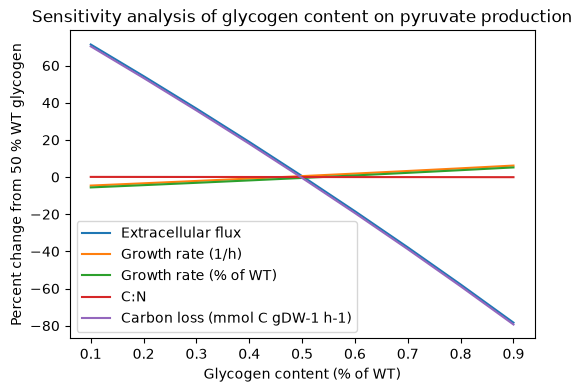

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Extracellular flux"] for row in glyc_rows], label="Extracellular flux")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Growth rate (1/h)"] for row in glyc_rows], label="Growth rate (1/h)")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Growth rate (% of WT)"] for row in glyc_rows], label="Growth rate (% of WT)")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["C:N"] for row in glyc_rows], label="C:N")
ax.plot(np.arange(0.1, 1.0, 0.1), [row["Carbon loss (mmol C gDW-1 h-1)"] for row in glyc_rows], label="Carbon loss (mmol C gDW-1 h-1)")
ax.set_xlabel("Glycogen content (% of WT)")
ax.set_ylabel("Percent change from 50 % WT glycogen")
ax.set_title("Sensitivity analysis of glycogen content on pyruvate production")
ax.legend()

fig.show()


In [20]:
recs = []
for x in np.arange(0.0, 1.01, 0.1):
    s = lgs_model(syn6803, glycogen_WT * x)
    for n, moi in export_dict.items():
        r = table2(s, n, moi, PHOTONS_WT, growth_WT, atp_WT/nadph_WT, glycogen_WT * x)
        recs.append(dict(glycogen_pct_of_WT=round(x * 100),
                            metabolite=n, flux=r["Extracellular flux"],
                            growth=r["Growth rate (1/h)"],
                            growth_pct=r["Growth rate (% of WT)"],
                            CN=r["C:N"], C_loss=r["Carbon loss (mmol C gDW-1 h-1)"]))
sens = pd.DataFrame(recs)

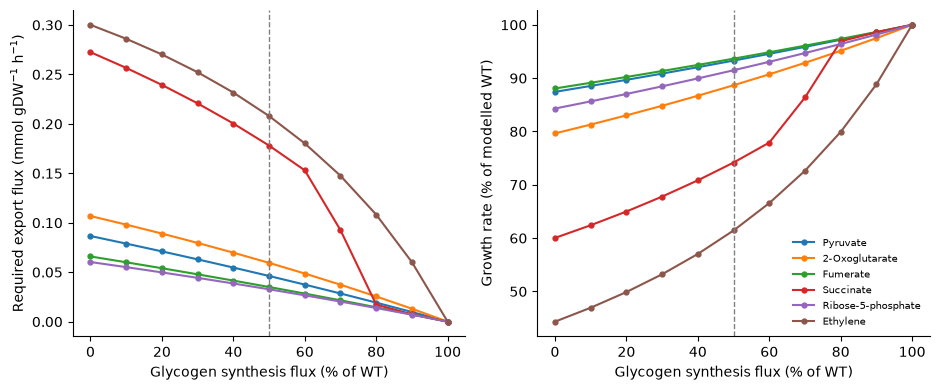

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4))
for n in export_dict.keys():
    d = sens[sens.metabolite == n].sort_values("glycogen_pct_of_WT")
    ax[0].plot(d.glycogen_pct_of_WT, d.flux, marker="o", ms=3.5, label=n)
    ax[1].plot(d.glycogen_pct_of_WT, d.growth_pct, marker="o", ms=3.5, label=n)
for a in ax:
    a.axvline(0.5 * 100, ls="--", lw=1, color="0.5")
    a.set_xlabel("Glycogen synthesis flux (% of WT)")
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("Required export flux (mmol gDW$^{-1}$ h$^{-1}$)")
ax[1].set_ylabel("Growth rate (% of modelled WT)")
ax[1].legend(fontsize=7.5, frameon=False, loc="lower right")
fig.tight_layout()
fig.show()